In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

import warnings
warnings.filterwarnings("ignore")

sns.set_theme(style="whitegrid")

In [ ]:
train = pd.read_csv("dataset_B_training.csv")
test = pd.read_csv("dataset_B_testing.csv")

print("Training dataset shape:", train.shape)
print("Testing dataset shape:", test.shape)

display(train.head())
display(test.head())

Training dataset shape: (4756, 31)
Testing dataset shape: (4749, 30)


,respondent_id,h1n1_concern,h1n1_knowledge,behavioral_antiviral_meds,behavioral_avoidance,behavioral_face_mask,behavioral_wash_hands,behavioral_large_gatherings,behavioral_outside_home,behavioral_touch_face,...,income_poverty,marital_status,rent_or_own,employment_status,census_msa,household_adults,household_children,employment_sector,number_chronic_med_conditions,h1n1_vaccine
0,1,1.0,2.0,0.0,1.0,0.0,1.0,0.0,0.0,1.0,...,"<= $75,000, Above Poverty",Married,Own,Employed,"MSA, Not Principle City",2.0,1.0,science,0,0
1,2,1.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,...,Below Poverty,Not Married,Own,Employed,Non-MSA,0.0,3.0,wholesale,0,0
2,3,2.0,1.0,0.0,1.0,0.0,1.0,0.0,0.0,1.0,...,"> $75,000",Not Married,Own,Employed,"MSA, Principle City",0.0,0.0,education,0,1
3,4,0.0,1.0,0.0,1.0,0.0,1.0,0.0,0.0,1.0,...,"<= $75,000, Above Poverty",Not Married,Rent,Not in Labor Force,Non-MSA,0.0,0.0,NaN,0,0
4,5,2.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,...,NaN,Not Married,NaN,Unemployed,Non-MSA,3.0,0.0,NaN,0,0


,respondent_id,h1n1_concern,h1n1_knowledge,behavioral_antiviral_meds,behavioral_avoidance,behavioral_face_mask,behavioral_wash_hands,behavioral_large_gatherings,behavioral_outside_home,behavioral_touch_face,...,sex,income_poverty,marital_status,rent_or_own,employment_status,census_msa,household_adults,household_children,employment_sector,number_chronic_med_conditions
0,4757,1.0,1.0,0.0,1.0,0.0,1.0,0.0,0.0,0.0,...,Female,"<= $75,000, Above Poverty",Not Married,Own,Not in Labor Force,"MSA, Principle City",0.0,0.0,NaN,0
1,4758,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,...,Female,NaN,NaN,NaN,NaN,"MSA, Not Principle City",0.0,0.0,NaN,0
2,4759,1.0,1.0,0.0,1.0,0.0,1.0,0.0,0.0,0.0,...,Male,NaN,Married,Own,Not in Labor Force,"MSA, Principle City",1.0,0.0,NaN,0
3,4760,3.0,1.0,0.0,1.0,0.0,1.0,1.0,0.0,0.0,...,Male,"<= $75,000, Above Poverty",Not Married,Rent,Employed,Non-MSA,1.0,0.0,agriculture,1
4,4761,1.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,...,Male,"<= $75,000, Above Poverty",Not Married,Own,Employed,Non-MSA,0.0,0.0,wholesale,0


In [ ]:
print("Training Dataset Information:")
train.info()

print("\nStatistical Summary:")
display(train.describe(include="all").T)

print("\nColumn Names:")
print(train.columns.tolist())

print("\nDuplicate Rows:", train.duplicated().sum())
print("Duplicate Respondent IDs:",
      train["respondent_id"].duplicated().sum())

Training Dataset Information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 4756 entries, 0 to 4755
Data columns (total 31 columns):
 #   Column                         Non-Null Count  Dtype  
---  ------                         --------------  -----  
 0   respondent_id                  4756 non-null   int64  
 1   h1n1_concern                   4741 non-null   float64
 2   h1n1_knowledge                 4734 non-null   float64
 3   behavioral_antiviral_meds      4739 non-null   float64
 4   behavioral_avoidance           4729 non-null   float64
 5   behavioral_face_mask           4752 non-null   float64
 6   behavioral_wash_hands          4748 non-null   float64
 7   behavioral_large_gatherings    4747 non-null   float64
 8   behavioral_outside_home        4741 non-null   float64
 9   behavioral_touch_face          4736 non-null   float64
 10  doctor_recc_h1n1               4437 non-null   float64
 11  child_under_6_months           4622 non-null   float64
 12  health_worker     

,count,unique,top,freq,mean,std,min,25%,50%,75%,max
respondent_id,4756.0,NaN,NaN,NaN,2378.5,1373.08327,1.0,1189.75,2378.5,3567.25,4756.0
h1n1_concern,4741.0,NaN,NaN,NaN,1.658933,0.892478,0.0,1.0,2.0,2.0,3.0
h1n1_knowledge,4734.0,NaN,NaN,NaN,1.30714,0.612811,0.0,1.0,1.0,2.0,2.0
behavioral_antiviral_meds,4739.0,NaN,NaN,NaN,0.057396,0.232622,0.0,0.0,0.0,0.0,1.0
behavioral_avoidance,4729.0,NaN,NaN,NaN,0.74096,0.438154,0.0,0.0,1.0,1.0,1.0
behavioral_face_mask,4752.0,NaN,NaN,NaN,0.077652,0.267651,0.0,0.0,0.0,0.0,1.0
behavioral_wash_hands,4748.0,NaN,NaN,NaN,0.842039,0.364743,0.0,1.0,1.0,1.0,1.0
behavioral_large_gatherings,4747.0,NaN,NaN,NaN,0.359385,0.479871,0.0,0.0,0.0,1.0,1.0
behavioral_outside_home,4741.0,NaN,NaN,NaN,0.341278,0.474189,0.0,0.0,0.0,1.0,1.0
behavioral_touch_face,4736.0,NaN,NaN,NaN,0.704814,0.456174,0.0,0.0,1.0,1.0,1.0



Column Names:
['respondent_id', 'h1n1_concern', 'h1n1_knowledge', 'behavioral_antiviral_meds', 'behavioral_avoidance', 'behavioral_face_mask', 'behavioral_wash_hands', 'behavioral_large_gatherings', 'behavioral_outside_home', 'behavioral_touch_face', 'doctor_recc_h1n1', 'child_under_6_months', 'health_worker', 'health_insurance', 'opinion_h1n1_vacc_effective', 'opinion_h1n1_risk', 'opinion_h1n1_sick_from_vacc', 'age_group', 'education', 'race', 'sex', 'income_poverty', 'marital_status', 'rent_or_own', 'employment_status', 'census_msa', 'household_adults', 'household_children', 'employment_sector', 'number_chronic_med_conditions', 'h1n1_vaccine']

Duplicate Rows: 0
Duplicate Respondent IDs: 0


,Missing Values,Missing Percentage
employment_sector,2364,49.71
health_insurance,1925,40.48
income_poverty,712,14.97
doctor_recc_h1n1,319,6.71
rent_or_own,315,6.62
employment_status,235,4.94
marital_status,226,4.75
education,224,4.71
child_under_6_months,134,2.82
health_worker,131,2.75


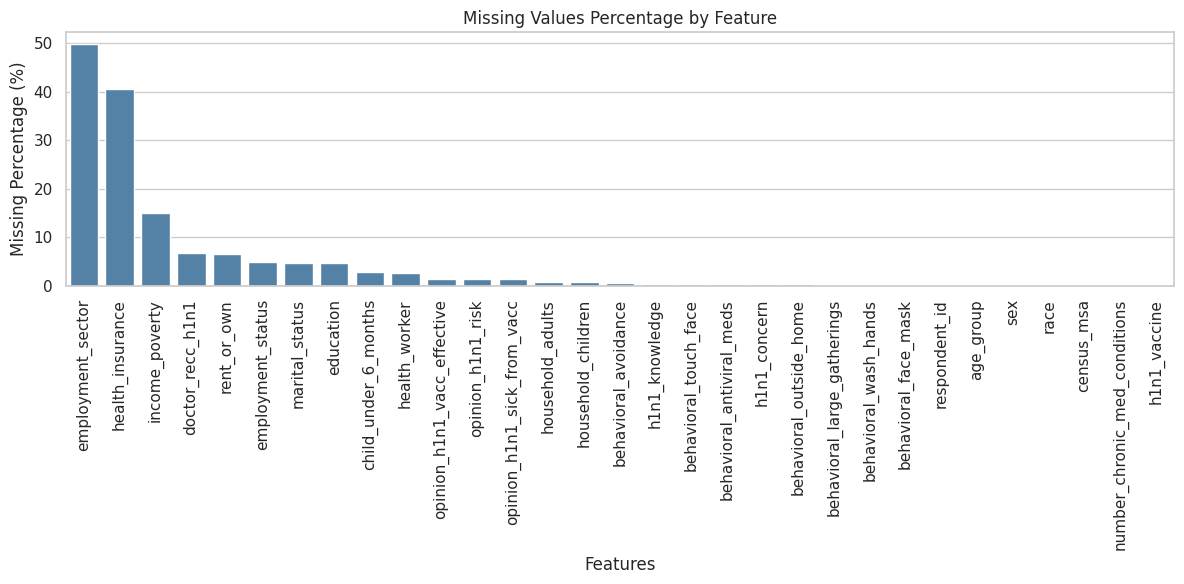

In [ ]:
missing = pd.DataFrame({
    "Missing Values": train.isnull().sum(),
    "Missing Percentage":
        (train.isnull().mean() * 100).round(2)
})

missing = missing.sort_values(
    "Missing Percentage", ascending=False
)

display(missing)

plt.figure(figsize=(12, 6))

sns.barplot(
    x=missing.index,
    y=missing["Missing Percentage"],
    color="steelblue"
)

plt.xticks(rotation=90)
plt.title("Missing Values Percentage by Feature")
plt.ylabel("Missing Percentage (%)")
plt.xlabel("Features")
plt.tight_layout()
plt.show()

h1n1_vaccine
0    2882
1    1874
Name: count, dtype: int64

Percentage Distribution:
h1n1_vaccine
0    60.6
1    39.4
Name: proportion, dtype: float64


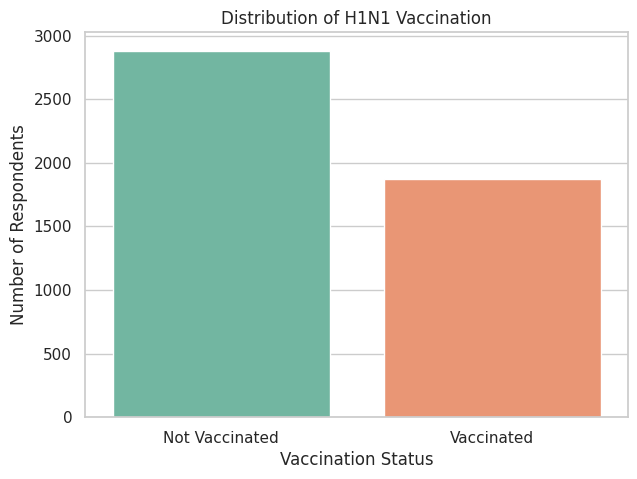

In [ ]:
print(train["h1n1_vaccine"].value_counts())

print("\nPercentage Distribution:")
print(
    train["h1n1_vaccine"]
    .value_counts(normalize=True)
    .mul(100)
    .round(2)
)

plt.figure(figsize=(7, 5))

sns.countplot(
    data=train,
    x="h1n1_vaccine",
    hue="h1n1_vaccine",
    palette="Set2",
    legend=False
)

plt.title("Distribution of H1N1 Vaccination")
plt.xlabel("Vaccination Status")
plt.ylabel("Number of Respondents")
plt.xticks([0, 1], ["Not Vaccinated", "Vaccinated"])
plt.show()

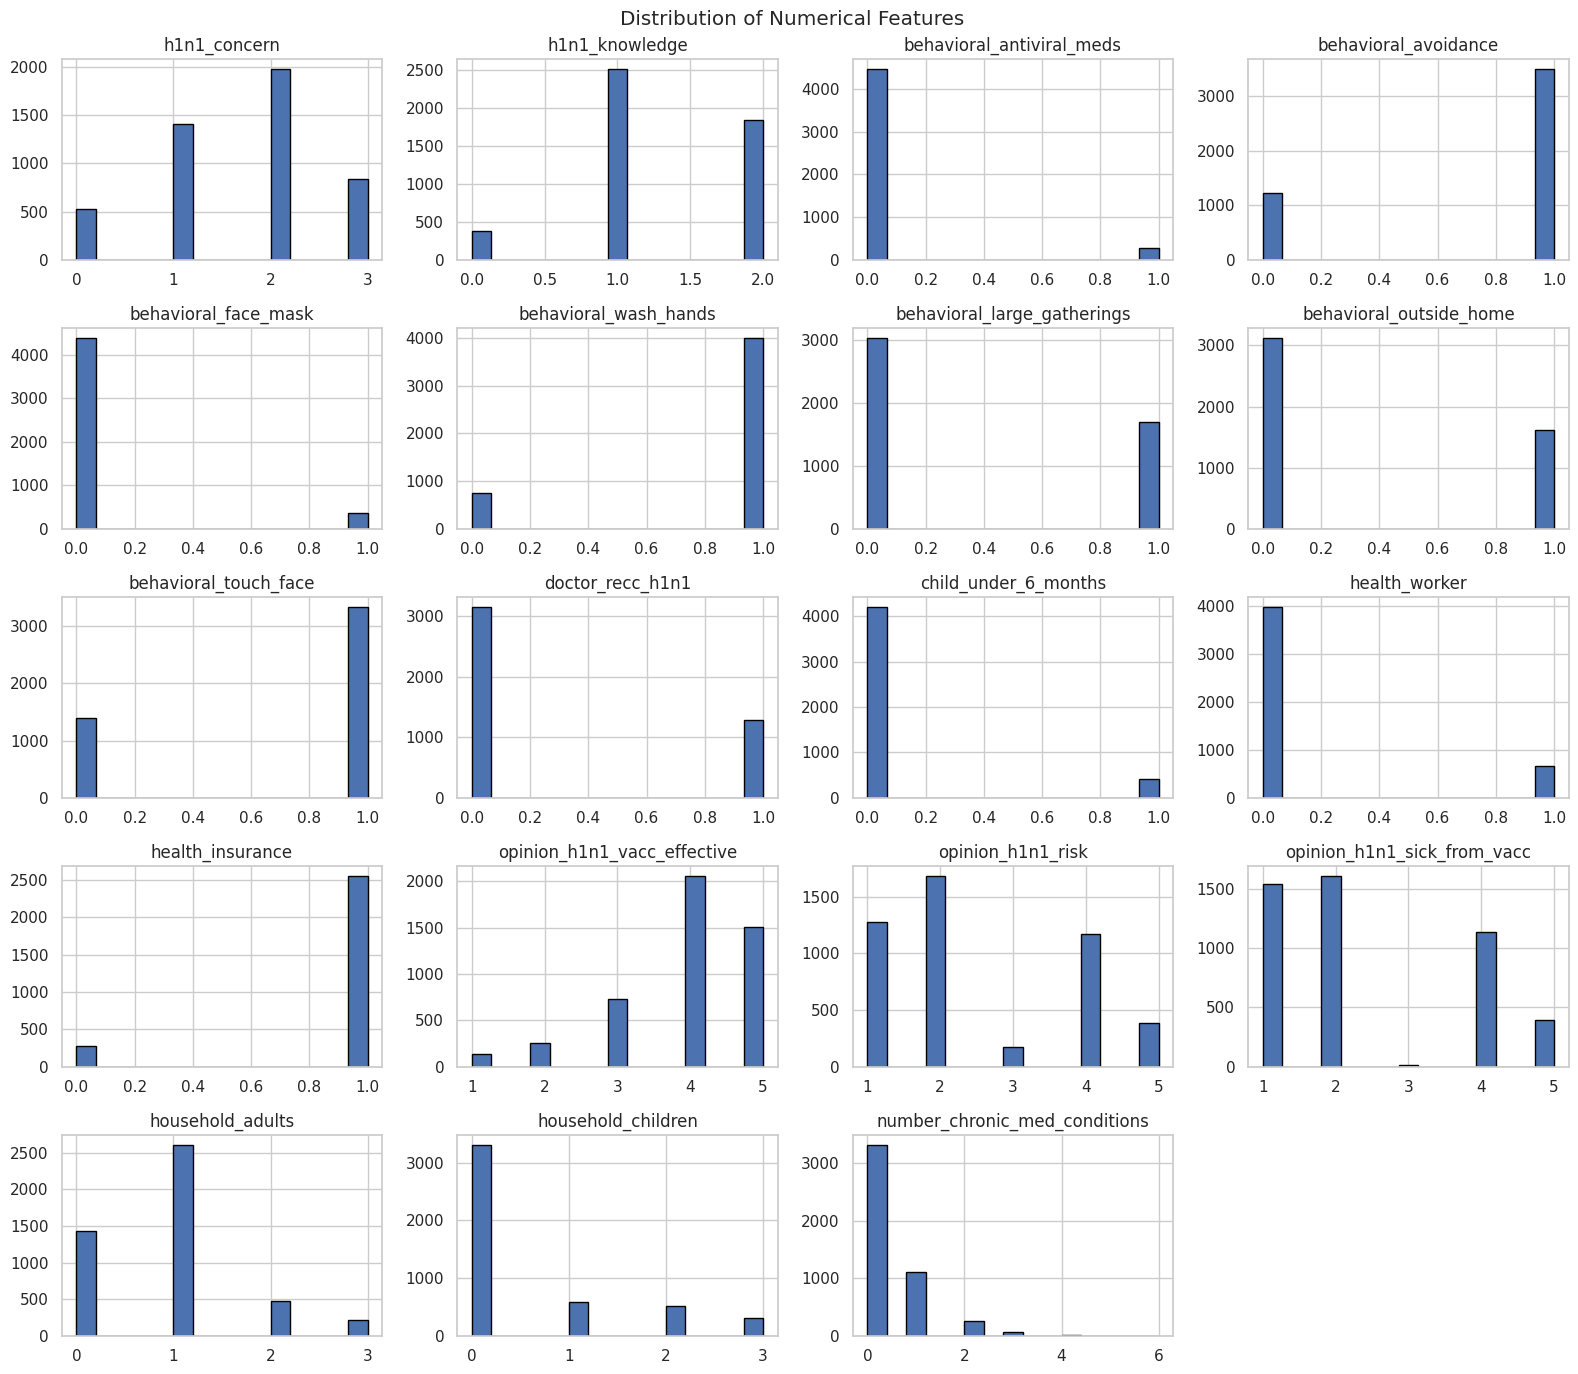

In [ ]:
numeric_cols = train.select_dtypes(
    include=["int64", "float64"]
).columns.drop(["respondent_id", "h1n1_vaccine"])

train[numeric_cols].hist(
    figsize=(16, 14),
    bins=15,
    edgecolor="black"
)

plt.suptitle("Distribution of Numerical Features")
plt.tight_layout()
plt.show()

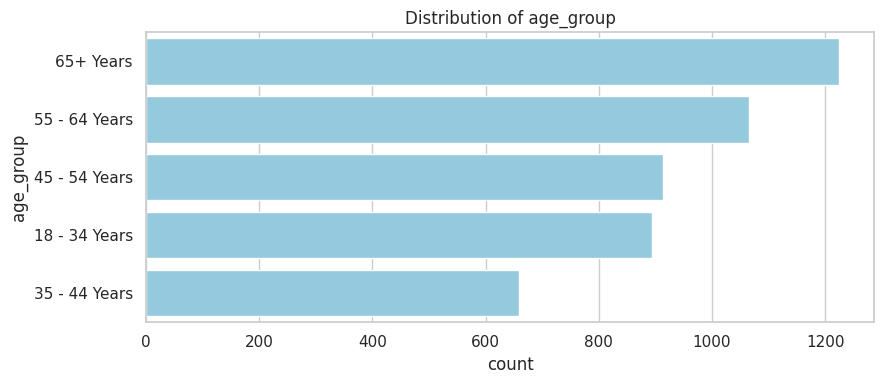

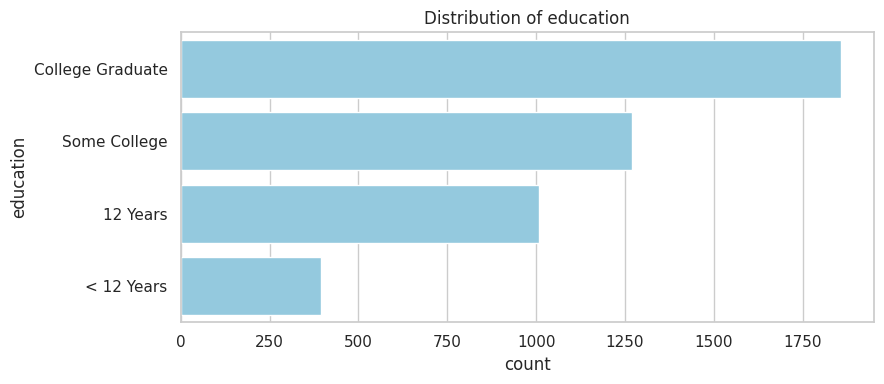

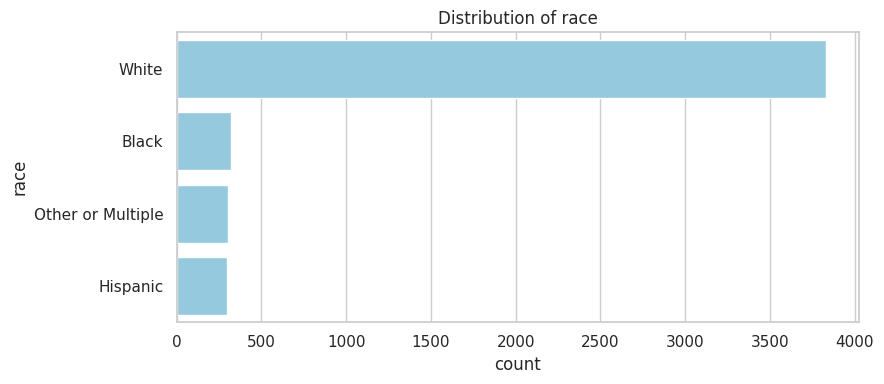

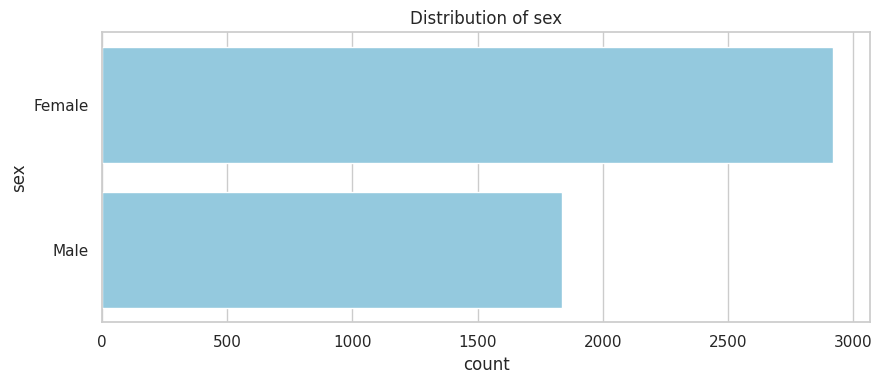

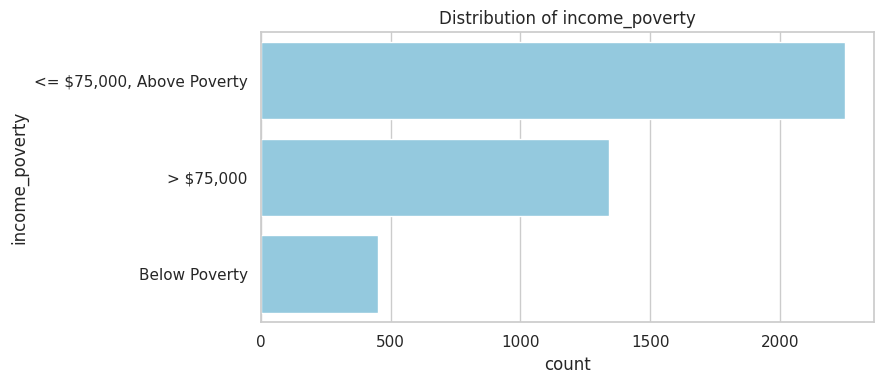

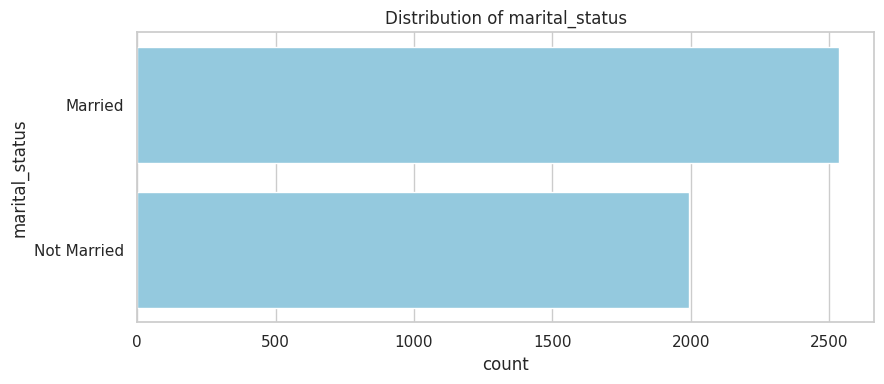

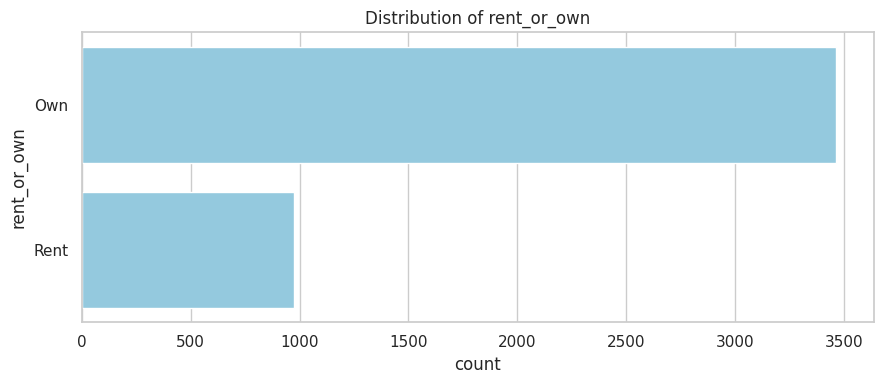

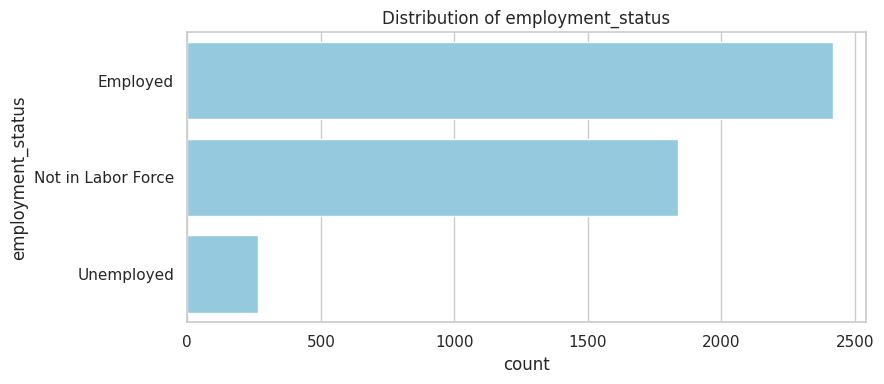

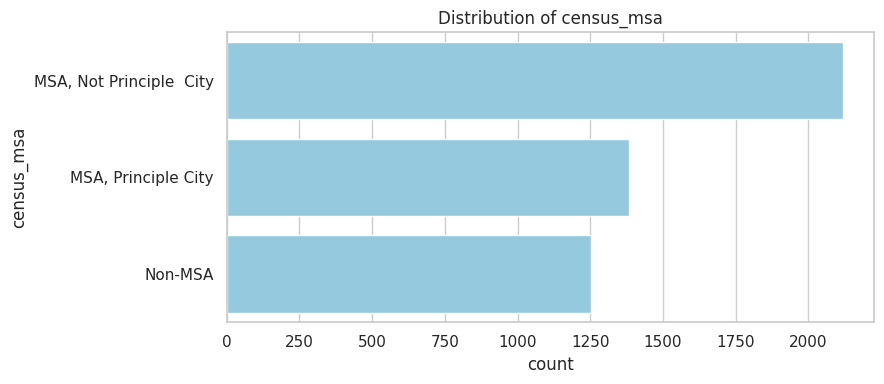

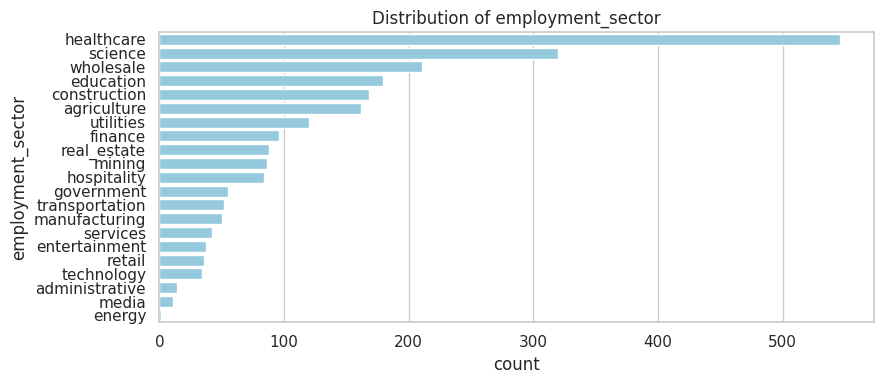

In [ ]:
categorical_cols = train.select_dtypes(
    include=["object"]
).columns

for col in categorical_cols:

    plt.figure(figsize=(9, 4))

    sns.countplot(
        data=train,
        y=col,
        order=train[col].value_counts().index,
        color="skyblue"
    )

    plt.title(f"Distribution of {col}")
    plt.tight_layout()
    plt.show()

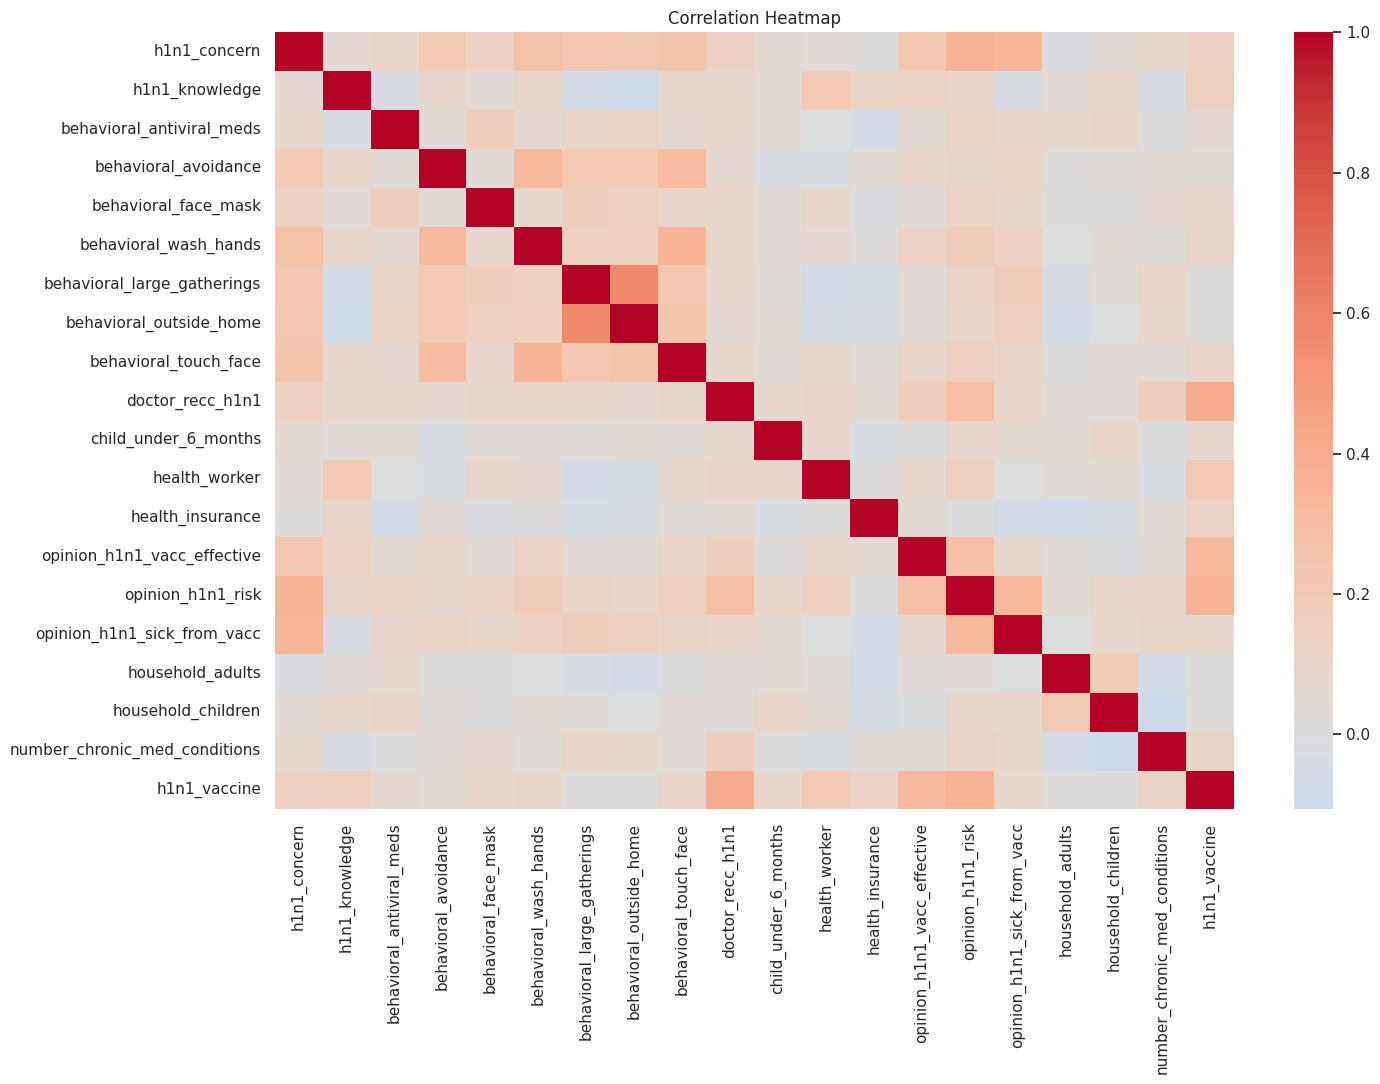

In [ ]:
plt.figure(figsize=(15, 11))

corr = train.select_dtypes(
    include=["number"]
).drop(columns=["respondent_id"]).corr()

sns.heatmap(
    corr,
    cmap="coolwarm",
    center=0,
    annot=False
)

plt.title("Correlation Heatmap")
plt.tight_layout()
plt.show()

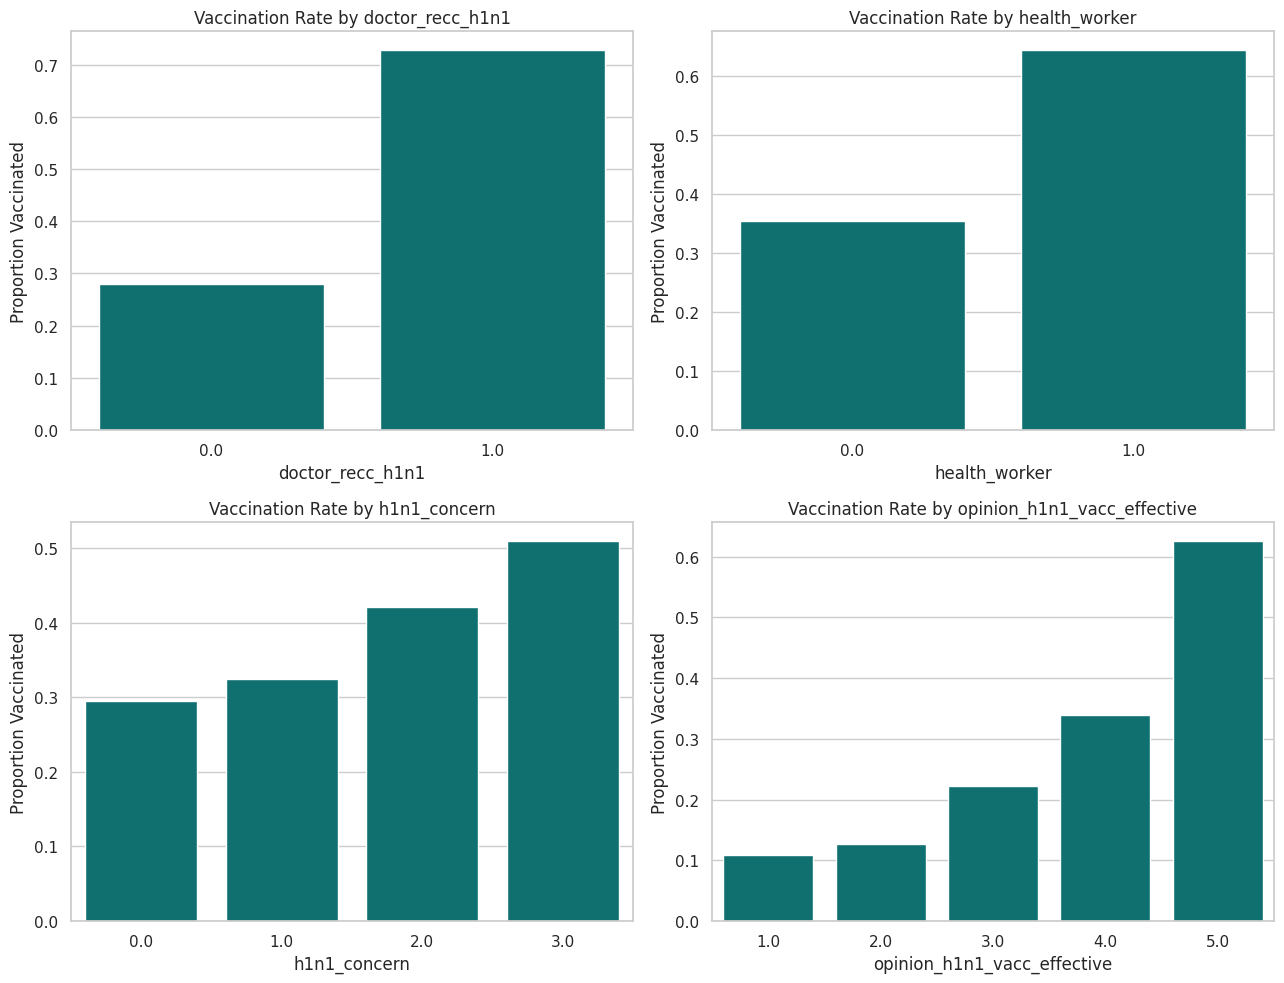

In [ ]:
features = [
    "doctor_recc_h1n1",
    "health_worker",
    "h1n1_concern",
    "opinion_h1n1_vacc_effective"
]

fig, axes = plt.subplots(2, 2, figsize=(13, 10))

for ax, feature in zip(axes.flat, features):

    sns.barplot(
        data=train,
        x=feature,
        y="h1n1_vaccine",
        ax=ax,
        color="teal",
        errorbar=None
    )

    ax.set_title(f"Vaccination Rate by {feature}")
    ax.set_ylabel("Proportion Vaccinated")

plt.tight_layout()
plt.show()

In [ ]:
X = train.drop(
    columns=["respondent_id", "h1n1_vaccine"]
)

y = train["h1n1_vaccine"]

X_test_final = test.drop(
    columns=["respondent_id"]
)

print("Features:", X.shape)
print("Target:", y.shape)
print("Final Test:", X_test_final.shape)

assert list(X.columns) == list(X_test_final.columns)

Features: (4756, 29)
Target: (4756,)
Final Test: (4749, 29)


In [ ]:
from sklearn.model_selection import train_test_split

X_train, X_val, y_train, y_val = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

print("Training size:", X_train.shape)
print("Validation size:", X_val.shape)

Training size: (3804, 29)
Validation size: (952, 29)


In [ ]:
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import (
    OneHotEncoder,
    StandardScaler
)
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline

numerical_features = X.select_dtypes(
    include=["int64", "float64"]
).columns.tolist()

categorical_features = X.select_dtypes(
    include=["object", "category"]
).columns.tolist()

numeric_transformer = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler())
])

categorical_transformer = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("encoder", OneHotEncoder(
        handle_unknown="ignore"
    ))
])

preprocessor = ColumnTransformer(
    transformers=[
        ("num", numeric_transformer, numerical_features),
        ("cat", categorical_transformer, categorical_features)
    ]
)

print("Numerical features:", len(numerical_features))
print("Categorical features:", len(categorical_features))

Numerical features: 19
Categorical features: 10


In [ ]:
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from xgboost import XGBClassifier

from sklearn.pipeline import Pipeline

models = {
    "Logistic Regression": LogisticRegression(
        max_iter=2000,
        random_state=42
    ),

    "Random Forest": RandomForestClassifier(
        n_estimators=300,
        max_depth=12,
        min_samples_leaf=2,
        random_state=42,
        n_jobs=-1
    ),

    "XGBoost": XGBClassifier(
        n_estimators=300,
        max_depth=4,
        learning_rate=0.05,
        subsample=0.8,
        colsample_bytree=0.8,
        objective="binary:logistic",
        eval_metric="logloss",
        random_state=42,
        n_jobs=-1
    )
}

In [ ]:
trained_models = {}

for name, model in models.items():

    pipeline = Pipeline(steps=[
        ("preprocessor", preprocessor),
        ("classifier", model)
    ])

    pipeline.fit(X_train, y_train)

    trained_models[name] = pipeline

    print(f"{name} trained successfully!")

Logistic Regression trained successfully!
Random Forest trained successfully!
XGBoost trained successfully!


In [ ]:
predictions = {}
probabilities = {}

for name, model in trained_models.items():

    predictions[name] = model.predict(X_val)

    probabilities[name] = model.predict_proba(
        X_val
    )[:, 1]

    print(f"{name} predictions completed")

Logistic Regression predictions completed
Random Forest predictions completed
XGBoost predictions completed


In [ ]:
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    classification_report,
    confusion_matrix,
    RocCurveDisplay
)

results = []

for name in trained_models:

    y_pred = predictions[name]
    y_prob = probabilities[name]

    results.append({
        "Model": name,
        "Accuracy": accuracy_score(y_val, y_pred),
        "Precision": precision_score(
            y_val, y_pred, zero_division=0
        ),
        "Recall": recall_score(
            y_val, y_pred, zero_division=0
        ),
        "F1 Score": f1_score(
            y_val, y_pred, zero_division=0
        ),
        "ROC-AUC": roc_auc_score(y_val, y_prob)
    })

results_df = pd.DataFrame(results)

results_df = results_df.sort_values(
    by="ROC-AUC",
    ascending=False
)

display(results_df.round(4))

,Model,Accuracy,Precision,Recall,F1 Score,ROC-AUC
0,Logistic Regression,0.7605,0.7290,0.6240,0.6724,0.8166
2,XGBoost,0.7500,0.7021,0.6347,0.6667,0.8053
1,Random Forest,0.7500,0.7276,0.5840,0.6479,0.7994


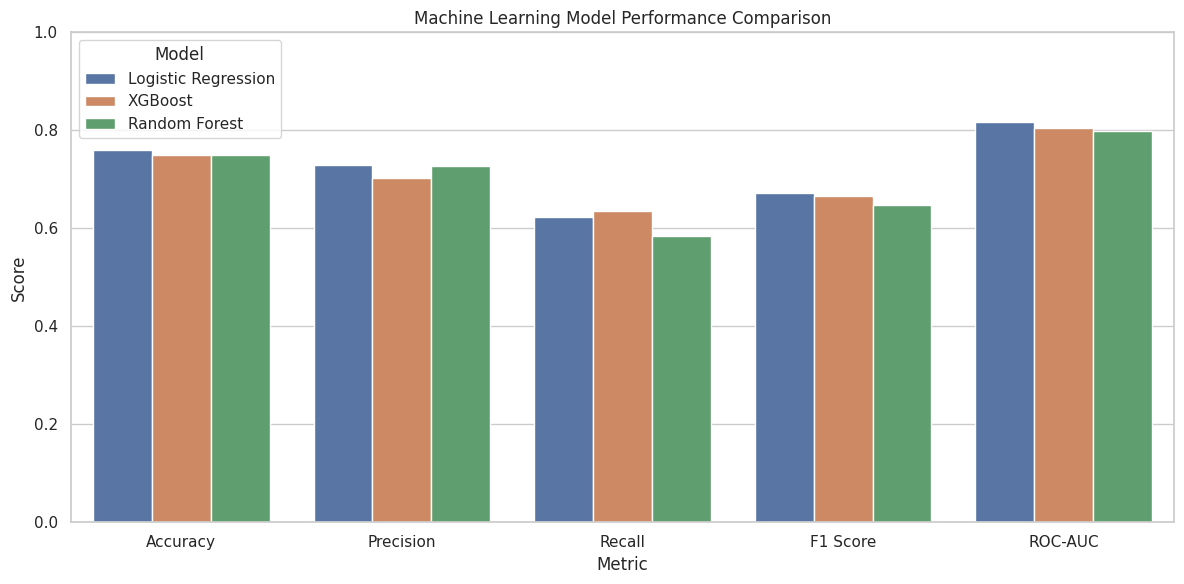

In [ ]:
metrics = [
    "Accuracy",
    "Precision",
    "Recall",
    "F1 Score",
    "ROC-AUC"
]

results_plot = results_df.melt(
    id_vars="Model",
    value_vars=metrics,
    var_name="Metric",
    value_name="Score"
)

plt.figure(figsize=(12, 6))

sns.barplot(
    data=results_plot,
    x="Metric",
    y="Score",
    hue="Model"
)

plt.title("Machine Learning Model Performance Comparison")
plt.ylim(0, 1)
plt.legend(title="Model")
plt.tight_layout()
plt.show()

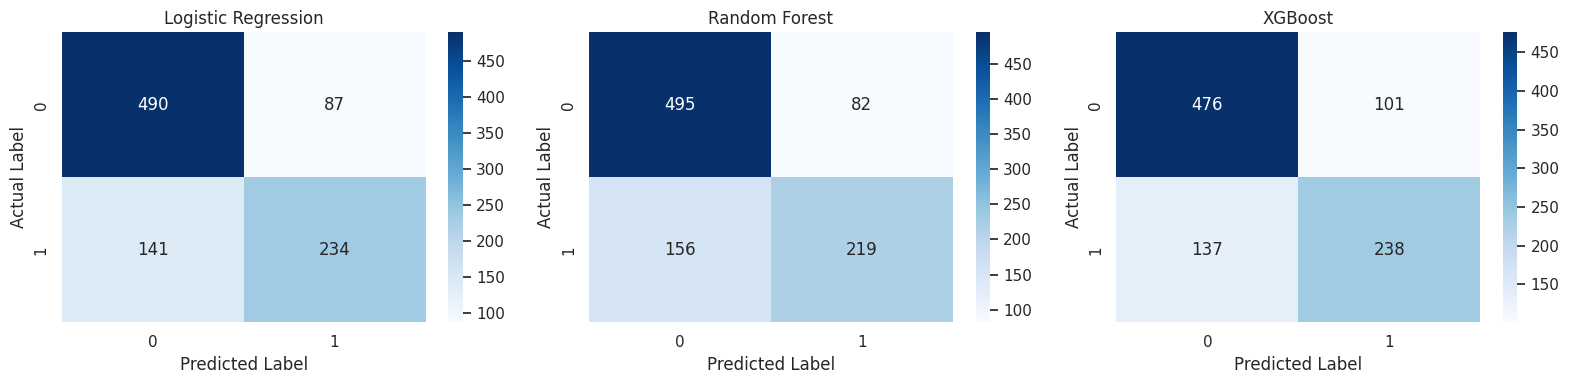

In [30]:
fig, axes = plt.subplots(1, 3, figsize=(16, 4))

for ax, name in zip(axes, trained_models):

    cm = confusion_matrix(
        y_val,
        predictions[name]
    )

    sns.heatmap(
        cm,
        annot=True,
        fmt="d",
        cmap="Blues",
        ax=ax
    )

    ax.set_title(name)
    ax.set_xlabel("Predicted Label")
    ax.set_ylabel("Actual Label")

plt.tight_layout()
plt.show()

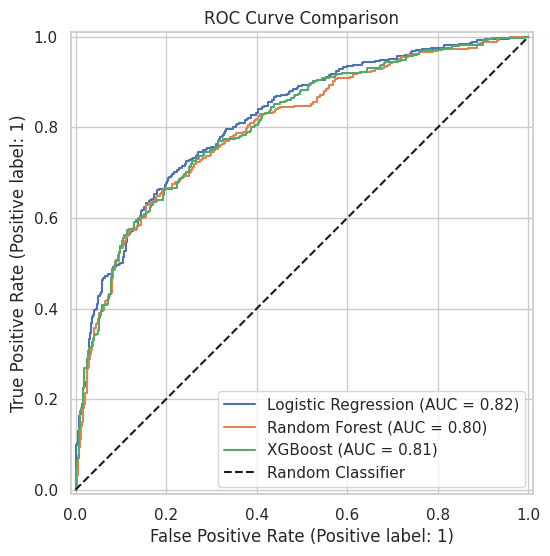

In [ ]:
fig, ax = plt.subplots(figsize=(8, 6))

for name, model in trained_models.items():

    RocCurveDisplay.from_predictions(
        y_val,
        probabilities[name],
        name=name,
        ax=ax
    )

plt.plot(
    [0, 1],
    [0, 1],
    "k--",
    label="Random Classifier"
)

plt.title("ROC Curve Comparison")
plt.legend()
plt.grid(True)
plt.show()

In [ ]:
for name in trained_models:

    print("\n" + "=" * 50)
    print(name)
    print("=" * 50)

    print(
        classification_report(
            y_val,
            predictions[name],
            zero_division=0
        )
    )


Logistic Regression
              precision    recall  f1-score   support

           0       0.78      0.85      0.81       577
           1       0.73      0.62      0.67       375

    accuracy                           0.76       952
   macro avg       0.75      0.74      0.74       952
weighted avg       0.76      0.76      0.76       952


Random Forest
              precision    recall  f1-score   support

           0       0.76      0.86      0.81       577
           1       0.73      0.58      0.65       375

    accuracy                           0.75       952
   macro avg       0.74      0.72      0.73       952
weighted avg       0.75      0.75      0.74       952


XGBoost
              precision    recall  f1-score   support

           0       0.78      0.82      0.80       577
           1       0.70      0.63      0.67       375

    accuracy                           0.75       952
   macro avg       0.74      0.73      0.73       952
weighted avg       0.75      

In [ ]:
best_model_name = results_df.iloc[0]["Model"]

best_model = trained_models[best_model_name]

print("Best Model:", best_model_name)

print(
    "Validation ROC-AUC:",
    round(results_df.iloc[0]["ROC-AUC"], 4)
)

Best Model: Logistic Regression
Validation ROC-AUC: 0.8166


,Feature,Importance
9,num__doctor_recc_h1n1,0.176266
14,num__opinion_h1n1_risk,0.143571
13,num__opinion_h1n1_vacc_effective,0.115774
15,num__opinion_h1n1_sick_from_vacc,0.033233
0,num__h1n1_concern,0.032386
11,num__health_worker,0.030529
1,num__h1n1_knowledge,0.026977
18,num__number_chronic_med_conditions,0.022639
16,num__household_adults,0.020261
17,num__household_children,0.020205


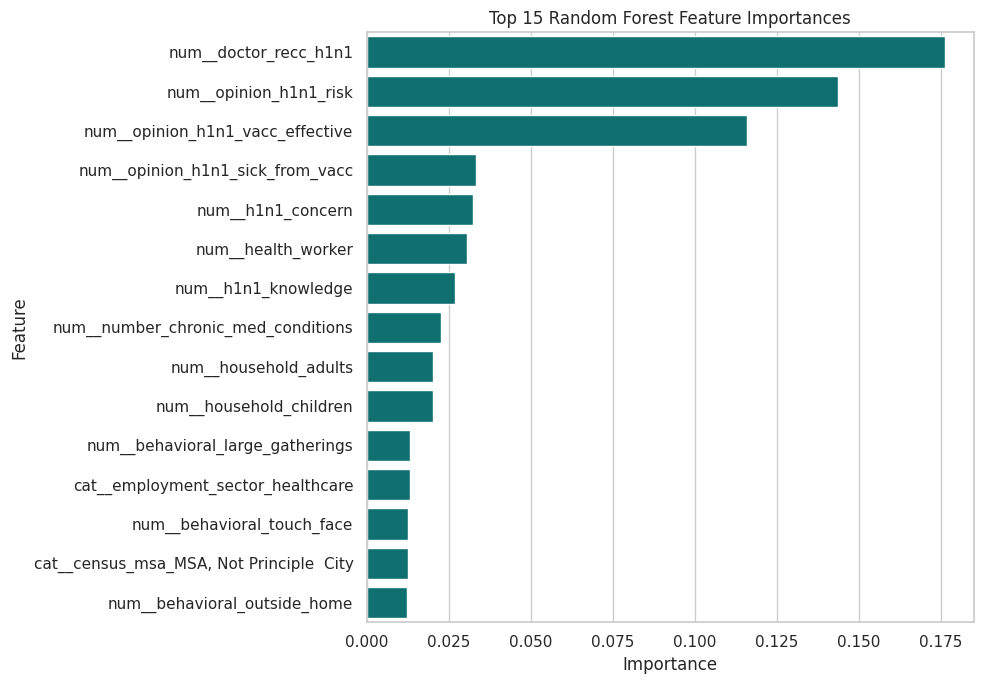

In [ ]:
rf_pipeline = trained_models["Random Forest"]

feature_names = (
    rf_pipeline.named_steps["preprocessor"]
    .get_feature_names_out()
)

importances = (
    rf_pipeline.named_steps["classifier"]
    .feature_importances_
)

importance_df = pd.DataFrame({
    "Feature": feature_names,
    "Importance": importances
}).sort_values(
    "Importance",
    ascending=False
)

display(importance_df.head(15))

plt.figure(figsize=(10, 7))

sns.barplot(
    data=importance_df.head(15),
    x="Importance",
    y="Feature",
    color="teal"
)

plt.title("Top 15 Random Forest Feature Importances")
plt.tight_layout()
plt.show()

In [ ]:
from sklearn.base import clone

final_model = clone(best_model)

final_model.fit(X, y)

print("Final model trained:", best_model_name)

Final model trained: Logistic Regression


In [ ]:
final_predictions = final_model.predict(
    X_test_final
)

final_probabilities = final_model.predict_proba(
    X_test_final
)[:, 1]

print("Total predictions:", len(final_predictions))

print(
    "Prediction distribution:",
    np.unique(
        final_predictions,
        return_counts=True
    )
)

Total predictions: 4749
Prediction distribution: (array([0, 1]), array([3122, 1627]))


In [ ]:
submission = pd.DataFrame({
    "respondent_id": test["respondent_id"],
    "h1n1_vaccine": final_predictions.astype(int)
})

display(submission.head(10))

submission.to_csv(
    "dataset_B_submission.csv",
    index=False
)

print("Submission file saved successfully!")

,respondent_id,h1n1_vaccine
0,4757,0
1,4758,0
2,4759,0
3,4760,0
4,4761,0
5,4762,1
6,4763,1
7,4764,1
8,4765,1
9,4766,0


Submission file saved successfully!


In [ ]:
print("Submission Shape:", submission.shape)

print("\nMissing Values:")
print(submission.isnull().sum())

print("\nDuplicate IDs:")
print(submission["respondent_id"].duplicated().sum())

print("\nPrediction Values:")
print(submission["h1n1_vaccine"].value_counts())

assert len(submission) == len(test)
assert submission["respondent_id"].equals(
    test["respondent_id"]
)
assert submission["h1n1_vaccine"].isin([0, 1]).all()

print("\nSubmission validation passed!")

Submission Shape: (4749, 2)

Missing Values:
respondent_id    0
h1n1_vaccine     0
dtype: int64

Duplicate IDs:
0

Prediction Values:
h1n1_vaccine
0    3122
1    1627
Name: count, dtype: int64

Submission validation passed!


In [ ]:
results_df.to_csv(
    "dataset_B_model_performance.csv",
    index=False
)

importance_df.to_csv(
    "dataset_B_feature_importance.csv",
    index=False
)

In [ ]:
import joblib

joblib.dump(
    final_model,
    "dataset_B_best_model.pkl"
)

print("Model saved successfully!")

Model saved successfully!


In [ ]:
loaded_model = joblib.load(
    "dataset_B_best_model.pkl"
)

sample_predictions = loaded_model.predict(
    X_test_final.head(5)
)

print("Sample Predictions:", sample_predictions)

Sample Predictions: [0 0 0 0 0]
